# 02 — Preparación de datos y Aprendizaje No Supervisado
## EP2 — MLY1101 Machine Learning | Caso C: Spotify Tracks

Este notebook cubre dos fases de CRISP-DM:

- **Fase 3 (Preparación de datos):** ejecuta, sobre el dataset completo, todas las decisiones justificadas en `01_EDA.ipynb` (consolidación de duplicados, tratamiento de ceros disfrazados, feature engineering), y luego realiza el split train/test.
- **Fase 4a (Aprendizaje No Supervisado):** PCA y K-Means sobre las variables de audio de Train, para descubrir "perfiles sonoros" de canciones, sin usar `popularity` en el proceso de clustering.

Toda la lógica reutilizable vive en `src/` (`preprocessing.py`, `pipeline.py`, `unsupervised.py`) — este notebook la importa y la ejecuta paso a paso, mostrando resultados intermedios para la defensa.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Permite importar el paquete src/ desde notebooks/
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

from src import config
from src import preprocessing as prep
from src import pipeline as pl
from src import unsupervised as unsup

print("Entorno configurado. Rutas:")
print(f"  RAW_DATA_PATH   = {config.RAW_DATA_PATH}")
print(f"  CLEAN_DATA_PATH = {config.CLEAN_DATA_PATH}")
print(f"  TRAIN_DATA_PATH = {config.TRAIN_DATA_PATH}")
print(f"  TEST_DATA_PATH  = {config.TEST_DATA_PATH}")

Entorno configurado. Rutas:
  RAW_DATA_PATH   = /home/lopresti/Documentos/Spotify-Tracks-Dataset/data/raw/dataset.csv
  CLEAN_DATA_PATH = /home/lopresti/Documentos/Spotify-Tracks-Dataset/data/processed/dataset_limpio.csv
  TRAIN_DATA_PATH = /home/lopresti/Documentos/Spotify-Tracks-Dataset/data/processed/train.csv
  TEST_DATA_PATH  = /home/lopresti/Documentos/Spotify-Tracks-Dataset/data/processed/test.csv


## 2. Carga del dataset crudo

In [2]:
df_raw = prep.cargar_datos()
print(f"Shape original: {df_raw.shape}")
df_raw.head()

Shape original: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 3. Limpieza estructural

Elimina la columna de índice residual (si existe), la fila con nulos triples y la canción con `duration_ms == 0` — hallazgos de la Fase 2 del EDA.

In [3]:
df_limpio_estructural = prep.limpieza_estructural(df_raw)

print(f"Shape antes:   {df_raw.shape}")
print(f"Shape después: {df_limpio_estructural.shape}")
print(f"Filas eliminadas: {df_raw.shape[0] - df_limpio_estructural.shape[0]}")

Shape antes:   (114000, 21)
Shape después: (113999, 20)
Filas eliminadas: 1


## 4. Feature engineering por fila

Operaciones deterministas, sin fuga de datos (no dependen de qué filas terminen en train o test):

- `tempo = 0` y `time_signature < 3` → `NaN` (fallas de detección del algoritmo de Spotify, Fase 2 EDA).
- `duration_min` reemplaza a `duration_ms`.
- `n_artistas` y `es_colaboracion`, a partir del campo `artists`.
- `es_version_multiple`: bandera 0/1 por canción (agrupando por `track_name` + `artists`, no solo `track_id` — ver Fase 2 del EDA).
- `macro_genero`: 114 géneros agrupados en 9 categorías, reservado exclusivamente para la auditoría ética en `06_model_evaluation` (no es feature del modelo).

In [4]:
df_features = prep.feature_engineering_por_fila(df_limpio_estructural)

print(f"tempo con NaN: {df_features['tempo'].isna().sum()}")
print(f"time_signature con NaN: {df_features['time_signature'].isna().sum()}")
print(f"Canciones en colaboración: {df_features['es_colaboracion'].sum()} ({df_features['es_colaboracion'].mean()*100:.1f}%)")
print(f"Canciones con versión múltiple: {df_features['es_version_multiple'].sum()} ({df_features['es_version_multiple'].mean()*100:.1f}%)")

df_features[["track_name", "artists", "duration_min", "n_artistas",
             "es_colaboracion", "es_version_multiple", "macro_genero"]].head()

tempo con NaN: 157
time_signature con NaN: 1136
Canciones en colaboración: 30075 (26.4%)
Canciones con versión múltiple: 21445 (18.8%)


,track_name,artists,duration_min,n_artistas,es_colaboracion,es_version_multiple,macro_genero
0,Comedy,Gen Hoshino,3.844433,1,0,0,clasica-instrumental
1,Ghost - Acoustic,Ben Woodward,2.493500,1,0,0,clasica-instrumental
2,To Begin Again,Ingrid Michaelson;ZAYN,3.513767,2,1,0,clasica-instrumental
3,Can't Help Falling In Love,Kina Grannis,3.365550,1,0,1,clasica-instrumental
4,Hold On,Chord Overstreet,3.314217,1,0,1,clasica-instrumental


## 5. Consolidación de duplicados (una fila por canción)

Se agrupa por `track_name` + `artists` y se conserva la fila de mayor `popularity` (el pico real de éxito de la canción). Justificado en la Fase 5 del EDA: la correlación entre `n_versiones` y `popularity_max` es prácticamente nula (0.001), confirmando que la popularidad fragmentada entre versiones es un artefacto de cómo Spotify registra republicaciones, no señal real.

In [5]:
df_limpio = prep.deduplicar(df_features)

print(f"Shape antes de consolidar:   {df_features.shape}")
print(f"Shape después de consolidar: {df_limpio.shape}")
print(f"Filas consolidadas: {df_features.shape[0] - df_limpio.shape[0]}")

Shape antes de consolidar:   (113999, 24)
Shape después de consolidar: (81343, 24)
Filas consolidadas: 32656


## 6. Split Train / Test (80/20, estratificado)

Estratificado por bucket de `popularity` para preservar la distribución multimodal del target (Fase 3 del EDA) en ambos conjuntos. A partir de aquí, cualquier estadístico (mediana, moda, escalas, categorías de One-Hot) se ajusta **solo con Train**.

In [6]:
train_df, test_df = prep.dividir_train_test(df_limpio)

print(f"Train: {train_df.shape} ({train_df.shape[0] / df_limpio.shape[0] * 100:.1f}%)")
print(f"Test:  {test_df.shape} ({test_df.shape[0] / df_limpio.shape[0] * 100:.1f}%)")

print("\nDistribución de popularity — Train vs Test (debe ser similar):")
print(pd.DataFrame({
    "train": train_df["popularity"].describe(),
    "test": test_df["popularity"].describe(),
}))

Train: (65074, 24) (80.0%)
Test:  (16269, 24) (20.0%)

Distribución de popularity — Train vs Test (debe ser similar):
              train          test
count  65074.000000  16269.000000
mean      35.262701     35.196017
std       19.422214     19.361853
min        0.000000      0.000000
25%       21.000000     21.000000
50%       35.000000     35.000000
75%       50.000000     49.000000
max       99.000000    100.000000


## 7. Guardado de datasets procesados

In [7]:
config.DATA_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

df_limpio.to_csv(config.CLEAN_DATA_PATH, index=False)
train_df.to_csv(config.TRAIN_DATA_PATH, index=False)
test_df.to_csv(config.TEST_DATA_PATH, index=False)

print("Guardado:")
print(f"  {config.CLEAN_DATA_PATH}")
print(f"  {config.TRAIN_DATA_PATH}")
print(f"  {config.TEST_DATA_PATH}")

Guardado:
  /home/lopresti/Documentos/Spotify-Tracks-Dataset/data/processed/dataset_limpio.csv
  /home/lopresti/Documentos/Spotify-Tracks-Dataset/data/processed/train.csv
  /home/lopresti/Documentos/Spotify-Tracks-Dataset/data/processed/test.csv


### Cierre — Fase 3 (Preparación de datos)

El dataset pasó de `df_raw.shape` filas crudas a un dataset consolidado de una fila por canción, con 6 variables nuevas (`duration_min`, `n_artistas`, `es_colaboracion`, `es_version_multiple`, `macro_genero`, y los `NaN` marcados en `tempo`/`time_signature`), dividido en Train/Test de forma estratificada. Ningún estadístico (imputación, escalado, encoding) se ha ajustado todavía — eso ocurre en el pipeline de `src/pipeline.py`, únicamente sobre Train, en la fase de modelamiento (notebook 03).

---
## 8. Aprendizaje No Supervisado — Fase 4a

Buscamos "perfiles sonoros" de canciones usando únicamente las variables de audio (`AUDIO_COLS`), sin usar `popularity` en el proceso de clustering — el cruce con popularidad se hace después, para interpretar los clusters, no para formarlos.

Se ajusta todo (`StandardScaler`, `PCA`, `K-Means`) sobre **Train**, para mantener Test como datos no vistos.

### 8.1 Escalado de variables de audio (solo Train)

In [8]:
X_train_audio_scaled, scaler_audio = unsup.escalar_audio(train_df)

print(f"Shape escalado: {X_train_audio_scaled.shape}")
print(f"Media por columna (debe ser ~0): {X_train_audio_scaled.mean(axis=0).round(3)}")
print(f"Std por columna (debe ser ~1):   {X_train_audio_scaled.std(axis=0).round(3)}")

Shape escalado: (65074, 9)
Media por columna (debe ser ~0): [-0. -0.  0.  0.  0.  0. -0. -0. -0.]
Std por columna (debe ser ~1):   [1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 8.2 PCA

Retenemos suficientes componentes para explicar ~85% de la varianza. Recordemos del EDA que `energy`, `loudness` y `acousticness` están fuertemente correlacionadas entre sí (multicolinealidad) — PCA ayuda a condensar esa redundancia.

Componentes retenidos: 6
Varianza explicada acumulada: 0.898


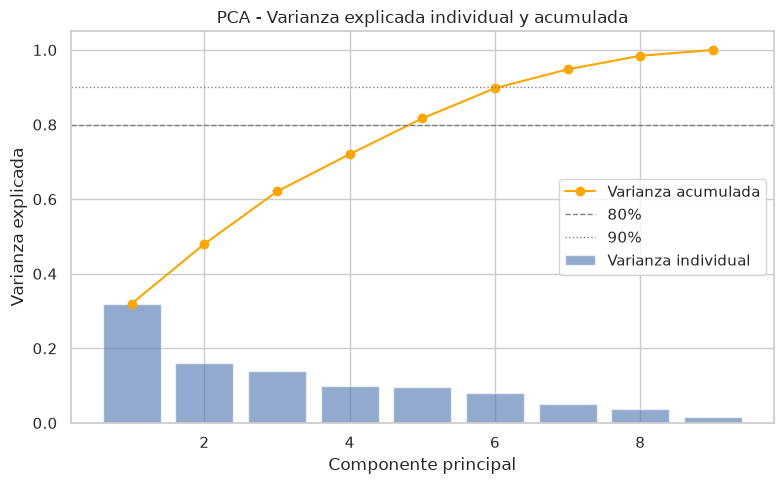

In [9]:
pca, X_train_pca, varianza_acumulada = unsup.aplicar_pca(X_train_audio_scaled, varianza_objetivo=0.85)

print(f"Componentes retenidos: {pca.n_components_}")
print(f"Varianza explicada acumulada: {varianza_acumulada[pca.n_components_ - 1]:.3f}")

config.IMAGES_DIR.mkdir(parents=True, exist_ok=True)
unsup.graficar_varianza_explicada(varianza_acumulada, guardar_en=config.IMAGES_DIR / "pca_variance.png")
plt.show()

### 8.3 Búsqueda de K óptimo (Codo + Silueta)

In [10]:
resultados_k = unsup.evaluar_rango_k(X_train_pca, k_min=2, k_max=10)
resultados_k

,k,inercia,silueta
0,2,11589.908349,0.291097
1,3,10083.657712,0.195203
2,4,8949.309833,0.199516
3,5,8056.977117,0.207673
4,6,7183.591694,0.222334
5,7,6542.805840,0.232426
6,8,6100.162952,0.209778
7,9,5729.149267,0.214843
8,10,5460.312916,0.196947


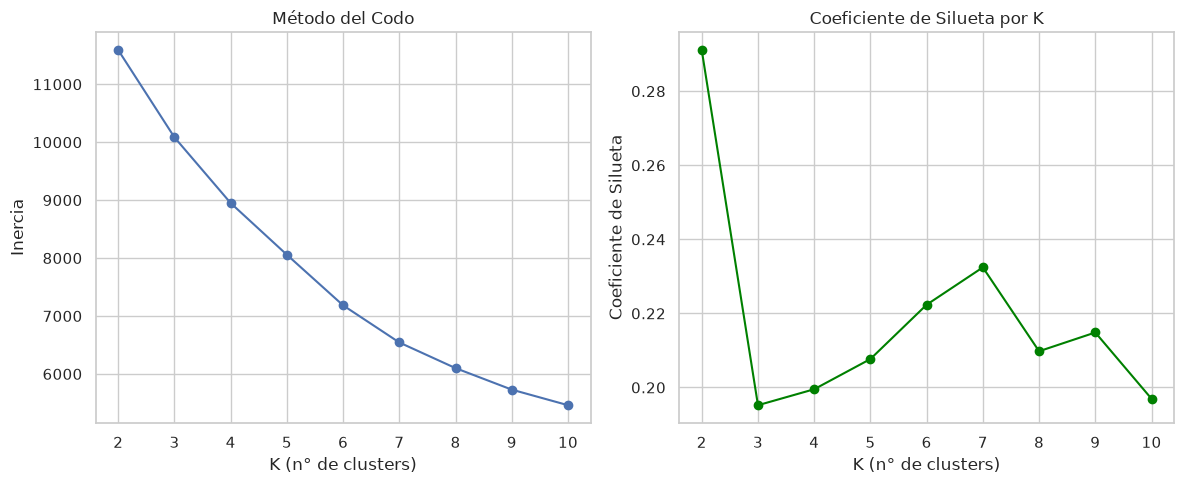

In [11]:
unsup.graficar_codo_y_silueta(resultados_k, guardar_en=config.IMAGES_DIR / "kmeans_elbow_silhouette.png")
plt.show()

**Elegir K:** revisar el gráfico de arriba — el "codo" en la curva de inercia y el pico del coeficiente de silueta. Ajustar `K_OPTIMO` en la celda siguiente según lo que se observe (valor de partida sugerido: donde la silueta es máxima).

In [13]:
K_OPTIMO = 7
print(f"K óptimo seleccionado (máxima silueta): {K_OPTIMO}")

K óptimo seleccionado (máxima silueta): 7


Interpretabilidad de negocio (K=2 es demasiado genérico para describir “perfiles sonoros”; K=7 da grupos más accionables), no por silueta.

### 8.4 K-Means final y visualización de clusters

In [19]:
kmeans_final, train_labels = unsup.entrenar_kmeans_final(X_train_pca, K_OPTIMO)

print(f"Distribución de canciones por cluster:")
print(pd.Series(train_labels).value_counts().sort_index())

Distribución de canciones por cluster:
0      812
1    12863
2     4669
3     5072
4    14567
5    19384
6     7707
Name: count, dtype: int64


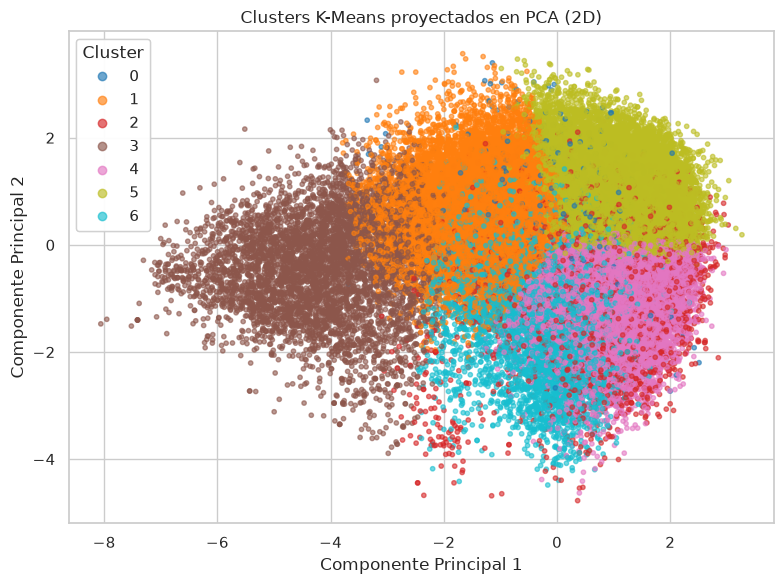

In [20]:
unsup.graficar_clusters_pca_2d(X_train_pca, train_labels, guardar_en=config.IMAGES_DIR / "pca_2d_clusters.png")
plt.show()

### 8.5 Perfilado de clusters

Promedio de variables clave por cluster — incluyendo `popularity`, que **no** se usó para formar los clusters, pero sí sirve para interpretarlos y conectar el hallazgo con el negocio.

In [21]:
perfil_clusters = unsup.perfilar_clusters(train_df, train_labels)
perfil_clusters

,danceability,energy,acousticness,valence,tempo,popularity
cluster,,,,,,
0,0.572,0.683,0.748,0.436,100.424,24.739
1,0.524,0.376,0.679,0.392,112.757,36.140
2,0.510,0.758,0.299,0.509,123.164,36.043
3,0.347,0.170,0.865,0.175,105.486,29.662
4,0.471,0.821,0.078,0.372,140.706,37.302
5,0.707,0.714,0.228,0.693,118.002,37.988
6,0.583,0.744,0.104,0.345,126.814,27.410


### 8.6 Clusters vs. track_genre

¿Los clusters (formados solo con audio) coinciden con los géneros musicales (que ya sabemos, por el EDA, que son la señal más fuerte del dataset)?

In [22]:
train_df_con_cluster = train_df.copy()
train_df_con_cluster["cluster"] = train_labels

tabla_cluster_genero = (
    train_df_con_cluster.groupby("cluster")["track_genre"]
    .apply(lambda s: s.value_counts().head(5))
)
tabla_cluster_genero

cluster                
0        comedy            640
         show-tunes         21
         kids               13
         children           13
         funk               12
1        tango             568
         romance           538
         honky-tonk        497
         cantopop          496
         show-tunes        465
2        pagode            342
         sertanejo         297
         samba             270
         gospel            148
         mpb               142
3        new-age           567
         sleep             554
         ambient           439
         piano             386
         classical         382
4        heavy-metal       550
         hardstyle         532
         metalcore         512
         grunge            415
         death-metal       408
5        kids              604
         salsa             577
         forro             522
         dancehall         497
         j-dance           457
6        detroit-techno    602
         minima

### Cierre — Fase 4a (Aprendizaje No Supervisado)

Completar tras revisar los resultados anteriores: cuántos clusters se retuvieron, qué "nombre de negocio" le damos a cada uno según su perfil de audio (ej. "instrumental-calmo", "energético-bailable"), si los clusters muestran diferencias de `popularity` entre sí, y si coinciden o no con los géneros musicales predominantes de cada grupo. Estas conclusiones alimentan el informe técnico (README) y la presentación.

---
## 9. Guardado de artefactos del no supervisado

In [23]:
import joblib

config.MODELS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(scaler_audio, config.MODELS_DIR / "scaler_audio.pkl")
joblib.dump(pca, config.MODELS_DIR / "pca_audio.pkl")
joblib.dump(kmeans_final, config.MODELS_DIR / "kmeans_final.pkl")

print("Modelos guardados en", config.MODELS_DIR)

Modelos guardados en /home/lopresti/Documentos/Spotify-Tracks-Dataset/models
